In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

In [2]:
df_path = "/content/drive/MyDrive/Model/Data sebelum imputasi/Data konsentrasi perjam DKI3 Jagakarsa.xlsx"
df = pd.read_excel(df_path)
df = df.replace('---', np.nan)
pollutant_cols = ['PM10', 'PM2.5', 'SO2', 'CO', 'O3', 'NO', 'NO2', 'NOX']
df[pollutant_cols] = df[pollutant_cols].replace(0, np.nan)
df.head(10)


/tmp/ipykernel_3418/67358231.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace('---', np.nan)


,datetime,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
0,2020-01-01 00:00:00,53.77,72.50,17.53,2.26,67.75,0.89,13.47,6.84,25.260000,1.19,24.070000,93.129997,0.755,0.000000
1,2020-01-01 01:00:00,60.61,41.57,17.36,1.4,71.46,NaN,4.52,2.08,25.430000,0.96,24.200001,92.919998,1.140,0.000000
2,2020-01-01 02:00:00,62,12.86,17.46,1.06,73,NaN,4.28,1.65,25.879999,0.67,23.590000,87.209999,1.830,0.000000
3,2020-01-01 03:00:00,61.2,5.52,17.31,1.15,62.1,0.32,1.16,NaN,25.990000,0.61,23.660000,87.010002,2.319,0.000000
4,2020-01-01 04:00:00,56.23,0.92,17.28,1.01,72.48,NaN,NaN,NaN,26.090000,0.82,23.940001,87.970001,2.548,0.000000
5,2020-01-01 05:00:00,48.59,NaN,17.33,0.9,80.31,NaN,NaN,NaN,26.780001,1.45,24.049999,85.019997,3.102,0.000000
6,2020-01-01 06:00:00,39.79,NaN,17.48,0.87,78.56,NaN,NaN,NaN,26.889999,1.85,24.129999,84.879997,2.361,33.830002
7,2020-01-01 07:00:00,26.78,NaN,17.45,0.9,74.69,NaN,NaN,NaN,26.480000,1.17,24.090000,86.739998,1.997,99.080002
8,2020-01-01 08:00:00,16.85,NaN,17.45,0.98,67.05,NaN,NaN,NaN,26.860001,1.20,23.920000,83.959999,1.917,147.220001
9,2020-01-01 09:00:00,12.59,NaN,17.55,1.08,62.5,NaN,NaN,NaN,26.900000,0.87,23.850000,83.410004,1.822,189.750000


In [3]:
for col in df.columns:
    if col != 'datetime':
        df[col] = pd.to_numeric(df[col], errors='coerce')
print(df.dtypes)

datetime                   datetime64[ns]
PM10                              float64
PM2.5                             float64
SO2                               float64
CO                                float64
O3                                float64
NO                                float64
NO2                               float64
NOX                               float64
Suhu Udara (°C)                   float64
Curah Hujan (mm)                  float64
Suhu Titik Embun (°C)             float64
Kelembaban Relatif (%)            float64
Kecepatan Angin (m/s)             float64
Radiasi Matahari (W/m²)           float64
dtype: object


In [4]:
df.isnull().sum()

,0
datetime,0
PM10,1689
PM2.5,1003
SO2,1448
CO,1000
O3,1737
NO,1227
NO2,2222
NOX,1246
Suhu Udara (°C),0


In [5]:
missing_percent = df.isnull().mean() * 100
missing_percent_str = missing_percent.round(2).astype(str) + ' %'
(missing_percent.round(2)).astype(str) + ' %'

,0
datetime,0.0 %
PM10,3.85 %
PM2.5,2.29 %
SO2,3.3 %
CO,2.28 %
O3,3.96 %
NO,2.8 %
NO2,5.07 %
NOX,2.84 %
Suhu Udara (°C),0.0 %


In [6]:
df_numeric = df.select_dtypes(include='number')
df_numeric.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
count,42159.00,42845.00,42400.00,42848.00,42111.00,42621.00,41626.00,42602.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00
mean,58.56,36.08,47.57,0.99,56.26,6.70,30.69,19.55,27.36,0.24,23.47,80.28,1.71,215.09
std,25.90,21.50,20.02,0.77,47.88,8.24,52.57,27.85,2.39,0.62,1.00,11.08,0.97,287.89
min,0.17,0.01,0.04,0.01,0.03,0.01,0.01,0.02,21.31,0.00,17.72,38.32,0.01,0.00
25%,39.95,20.86,30.26,0.49,19.49,2.86,10.19,7.85,25.36,0.00,22.99,72.52,1.01,0.00
50%,55.30,33.06,47.88,0.78,40.52,4.50,19.42,13.52,26.83,0.03,23.56,83.08,1.49,12.57
75%,73.70,47.07,61.15,1.25,80.74,7.11,34.81,22.81,29.24,0.18,24.12,89.56,2.23,430.59
max,254.46,270.65,191.84,11.63,431.60,396.88,1650.65,848.96,35.50,17.01,26.46,98.01,7.07,1056.86


In [8]:
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
df_ts = df.set_index('datetime')
df_ts = df_ts.apply(pd.to_numeric, errors='coerce')

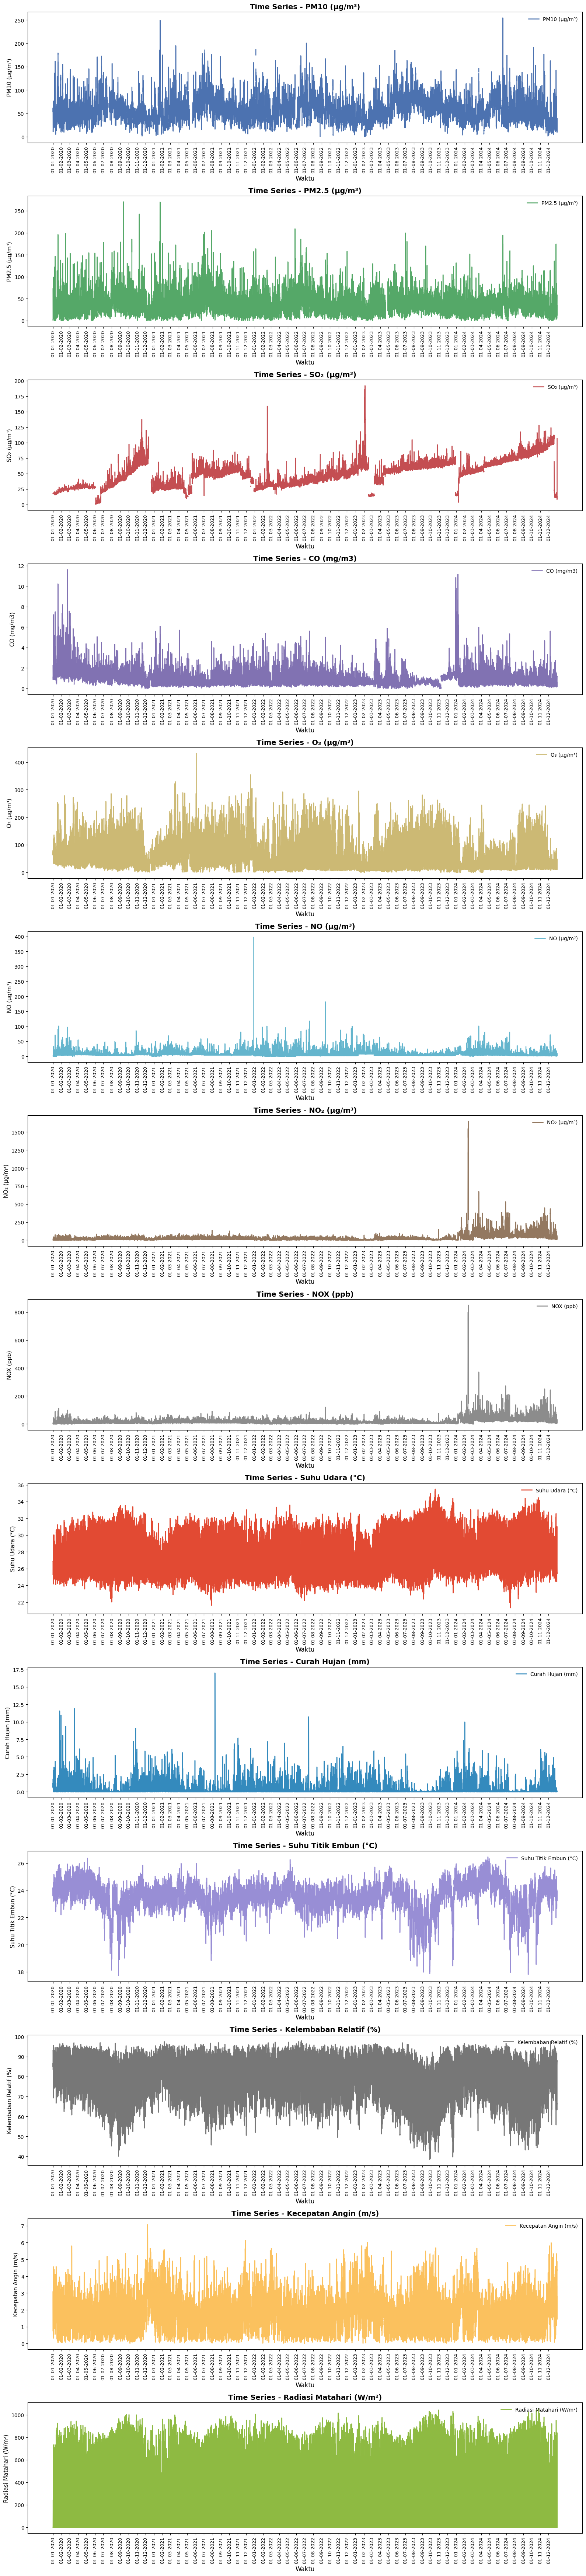

In [9]:
if not isinstance(df_ts.index, pd.DatetimeIndex):
    df_ts.index = pd.to_datetime(df_ts.index)

df_ts = df_ts.sort_index()
hours = (df_ts.index - df_ts.index.min()) / pd.Timedelta(hours=1)
xticks = pd.date_range(start=df_ts.index.min().normalize(),
                       end=df_ts.index.max().normalize(), freq="MS")
labels = [d.strftime('%d-%m-%Y') for d in xticks]


xticks_hours = (xticks - df_ts.index.min()) / pd.Timedelta(hours=1)

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_ts.columns) > len(colors):
    colors = (colors * (len(df_ts.columns) // len(colors) + 1))[:len(df_ts.columns)]

label_map = {
    'datetime': 'Tanggal & Waktu',
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (mg/m3)',
    'O3': 'O₃ (µg/m³)',
    'NO': 'NO (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'NOX': 'NOX (ppb)'
}

fig, axes = plt.subplots(
    nrows=len(df_ts.columns),
    figsize=(16, 5 * len(df_ts.columns)),
    sharex=False
)

if len(df_ts.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_ts.columns, colors):
    ax.plot(hours, df_ts[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu", fontsize=12)

plt.tight_layout()
plt.show()

In [10]:
df['datetime'] = pd.to_datetime(df['datetime'])
datetime_index = df['datetime']
numeric_cols = df.select_dtypes(include=[np.number]).columns
df_numeric = df[numeric_cols]

scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_numeric)

In [11]:
imputer = KNNImputer(n_neighbors=5)
df_imputed_scaled = imputer.fit_transform(df_scaled)

In [12]:
df_imputed_numeric = pd.DataFrame(
    scaler.inverse_transform(df_imputed_scaled),
    columns=numeric_cols
)

In [13]:
df_imputed = df_imputed_numeric.copy()
df_imputed.index = datetime_index
df_imputed.head(10)

,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
datetime,,,,,,,,,,,,,,
2020-01-01 00:00:00,53.77,72.500,17.53,2.26,67.75,0.890,13.470,6.840,25.260000,1.19,24.070000,93.129997,0.755,0.000000
2020-01-01 01:00:00,60.61,41.570,17.36,1.40,71.46,3.274,4.520,2.080,25.430000,0.96,24.200001,92.919998,1.140,0.000000
2020-01-01 02:00:00,62.00,12.860,17.46,1.06,73.00,2.248,4.280,1.650,25.879999,0.67,23.590000,87.209999,1.830,0.000000
2020-01-01 03:00:00,61.20,5.520,17.31,1.15,62.10,0.320,1.160,3.542,25.990000,0.61,23.660000,87.010002,2.319,0.000000
2020-01-01 04:00:00,56.23,0.920,17.28,1.01,72.48,2.562,4.758,5.036,26.090000,0.82,23.940001,87.970001,2.548,0.000000
2020-01-01 05:00:00,48.59,11.758,17.33,0.90,80.31,1.382,13.454,10.164,26.780001,1.45,24.049999,85.019997,3.102,0.000000
2020-01-01 06:00:00,39.79,14.992,17.48,0.87,78.56,2.384,12.614,9.124,26.889999,1.85,24.129999,84.879997,2.361,33.830002
2020-01-01 07:00:00,26.78,12.080,17.45,0.90,74.69,2.334,7.786,6.980,26.480000,1.17,24.090000,86.739998,1.997,99.080002
2020-01-01 08:00:00,16.85,2.792,17.45,0.98,67.05,2.778,7.978,6.096,26.860001,1.20,23.920000,83.959999,1.917,147.220001


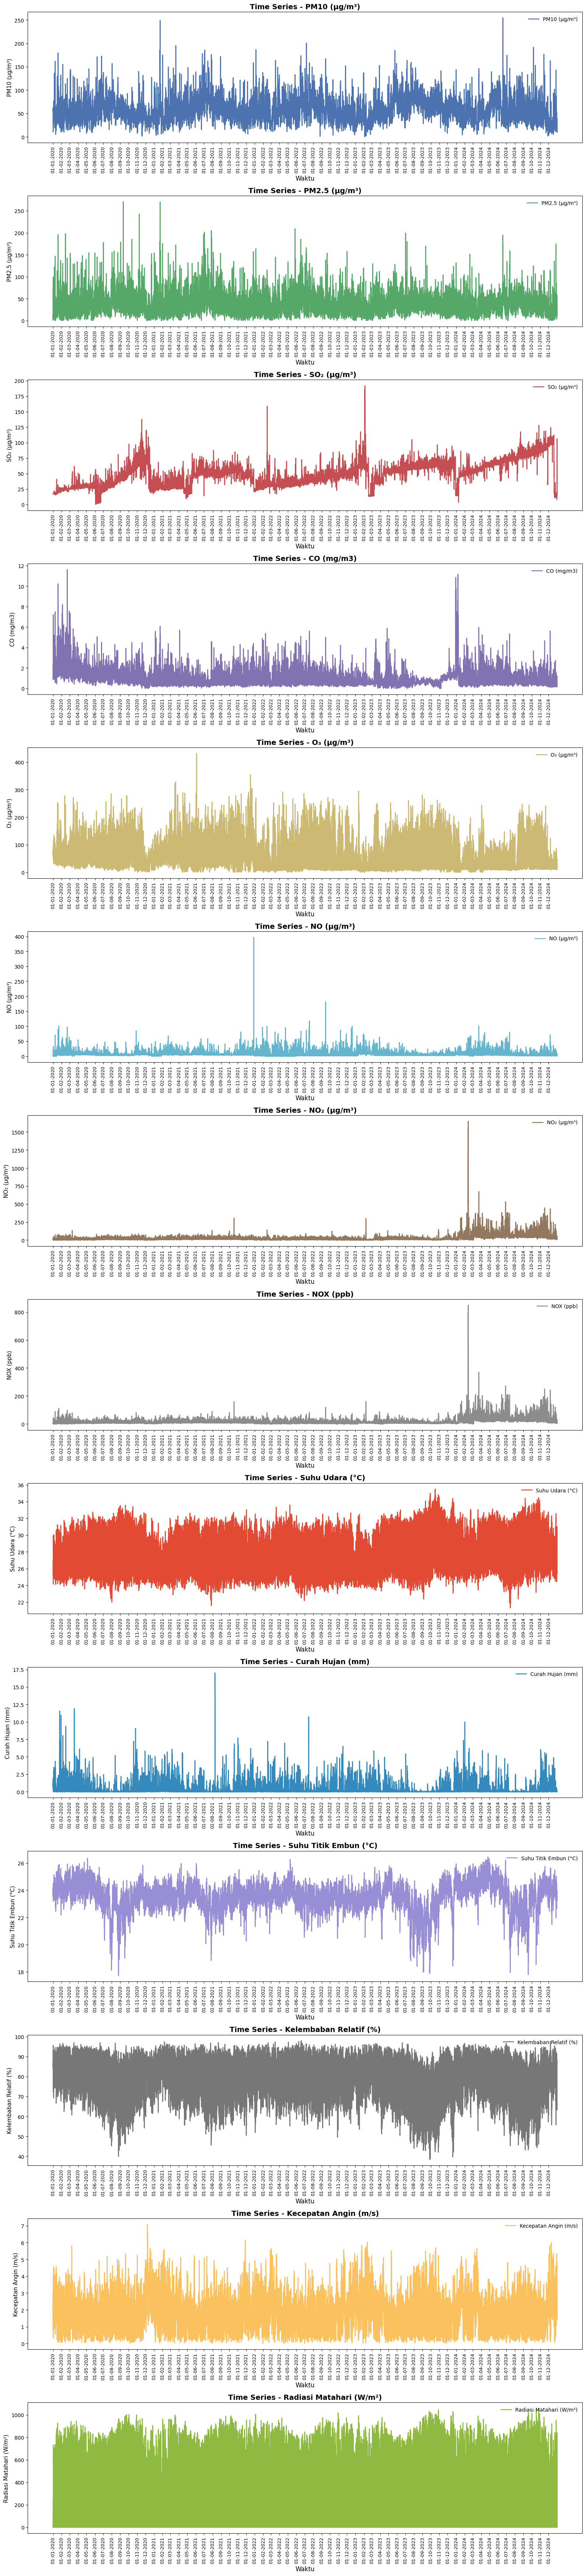

In [14]:
if not isinstance(df_imputed.index, pd.DatetimeIndex):
    df_imputed.index = pd.to_datetime(df_imputed.index)

df_imputed = df_imputed.sort_index()

hours = (df_imputed.index - df_imputed.index.min()) / pd.Timedelta(hours=1)

xticks = pd.date_range(start=df_imputed.index.min().normalize(),
                       end=df_imputed.index.max().normalize(),
                       freq="MS")
labels = [d.strftime('%d-%m-%Y') for d in xticks]
xticks_hours = (xticks - df_imputed.index.min()) / pd.Timedelta(hours=1)

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_imputed.columns) > len(colors):
    colors = (colors * (len(df_imputed.columns) // len(colors) + 1))[:len(df_imputed.columns)]

label_map = {
    'datetime': 'Tanggal & Waktu',
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (mg/m3)',
    'O3': 'O₃ (µg/m³)',
    'NO': 'NO (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'NOX': 'NOX (ppb)'
}

fig, axes = plt.subplots(
    nrows=len(df_imputed.columns),
    figsize=(16, 5 * len(df_imputed.columns)),
    sharex=False
)

if len(df_imputed.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_imputed.columns, colors):
    ax.plot(hours, df_imputed[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu", fontsize=12)

plt.tight_layout()
plt.show()

In [15]:
df_imputed.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
count,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00
mean,58.60,35.95,47.51,0.98,55.92,6.68,30.07,19.46,27.36,0.24,23.47,80.28,1.71,215.09
std,25.66,21.37,19.82,0.76,47.63,8.19,51.65,27.61,2.39,0.62,1.00,11.08,0.97,287.89
min,0.17,0.01,0.04,0.01,0.03,0.01,0.01,0.02,21.31,0.00,17.72,38.32,0.01,0.00
25%,40.14,20.85,30.57,0.50,19.45,2.87,9.84,7.83,25.36,0.00,22.99,72.52,1.01,0.00
50%,55.47,32.93,47.66,0.78,40.06,4.50,19.00,13.49,26.83,0.03,23.56,83.08,1.49,12.57
75%,73.51,46.82,60.89,1.25,80.06,7.11,34.10,22.72,29.24,0.18,24.12,89.56,2.23,430.59
max,254.46,270.65,191.84,11.63,431.60,396.88,1650.65,848.96,35.50,17.01,26.46,98.01,7.07,1056.86


In [16]:
df_imputed.loc[:, ~df_imputed.columns.isin(['NO', 'NOX'])].describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
count,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00
mean,58.60,35.95,47.51,0.98,55.92,30.07,27.36,0.24,23.47,80.28,1.71,215.09
std,25.66,21.37,19.82,0.76,47.63,51.65,2.39,0.62,1.00,11.08,0.97,287.89
min,0.17,0.01,0.04,0.01,0.03,0.01,21.31,0.00,17.72,38.32,0.01,0.00
25%,40.14,20.85,30.57,0.50,19.45,9.84,25.36,0.00,22.99,72.52,1.01,0.00
50%,55.47,32.93,47.66,0.78,40.06,19.00,26.83,0.03,23.56,83.08,1.49,12.57
75%,73.51,46.82,60.89,1.25,80.06,34.10,29.24,0.18,24.12,89.56,2.23,430.59
max,254.46,270.65,191.84,11.63,431.60,1650.65,35.50,17.01,26.46,98.01,7.07,1056.86


In [ ]:
df_imputed['datetime'] = df_imputed.index
df_imputed.to_excel("/content/drive/MyDrive/Model/Data Imputasi/df_imputed.xlsx", index=False)